In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from models.melodic_markov_model import MelodicMarkovModel
from priors.alpha_prior import get_d2g_alpha
from priors.transition_prior import TransitionPrior
import pymc as pm

# Model 1

## With Uninformative Priors

Model 1 is a simple Markov Model. The melody is generated by the following procedure:

* The length is drawn by a Poisson distribution with a fixed parameter that is the expected length l of the melody
* The probabilities for the last pitch (pi) and the transition probabilities for the markov chain (A) are drawn by Dirichlet Distributions
* The last pitch is drawn by a Categorical Distribution parametrized by pi.
* Then, the following pitches are generated in a loop of the drawn length with a Categorical Distribution parametrized by the row A_i with index x_{t-1}

At first, this is done with constant priors (Poisson: 20, Dirichlets: all ones)

In [3]:
m1_wo_priors = MelodicMarkovModel()
m1_wo_priors.build_model()

    pi ~ Dirichlet(<constant>)
     A ~ Dirichlet(<constant>)
   x_0 ~ Categorical(pi)
length ~ Poisson(40)
 x_t+1 ~ CustomDist_x_t+1(x_0, A, length)

With this priors, all pitches are equally likely.

In [4]:
samples = m1_wo_priors.prior_predict(3)
[m1_wo_priors.show_melody(s) for s in samples][0]

Sampling: [A, length, pi, x_0, x_t+1]
Sampling: [A, length, pi, x_0, x_t+1]
Sampling: [A, length, pi, x_0, x_t+1]


## With Informative Priors

Now, we set priors that are informed by music theoretic beliefs of the structure of medieval monophonic melodies. 
For "Gregorian Chant", that is structured by the concept of mode, we can simplify the prior of pi is 1 only for the four pitch indices of D, E, F, and G, which are the finals of the 8 modes. This is done with the method `get_d2g_alpha()`.

In [5]:
m1_inf_prior = MelodicMarkovModel()
m1_inf_prior.alpha = get_d2g_alpha(m1_inf_prior.V)

beta = TransitionPrior(m1_inf_prior.V)
beta.prefer_small_intervals(100,3)
beta.prefer_low_register(4,2,2)
beta.penalize_repeated_notes(0.5)
beta.dim_high_register(1)


m1_inf_prior.beta = beta.get_beta()

#m1_inf_prior.build_model()

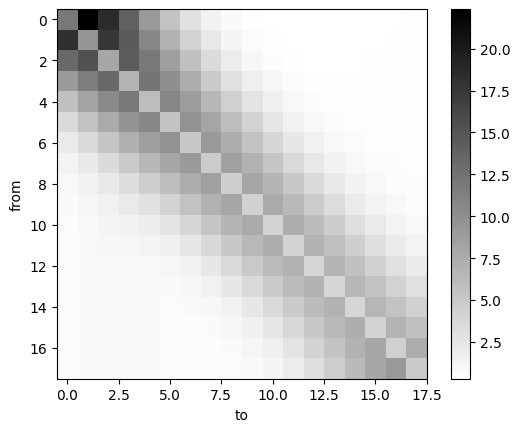

In [6]:
import models.model_utils as u
u.plot_heatmap(m1_inf_prior.beta)

In [7]:
samples = m1_inf_prior.prior_predict(2)
m1_inf_prior.show_melody(samples[1])

TypeError: 'NoneType' object does not support the context manager protocol

## Evaluation

We can use a simple criterion for evaluation of the prior, e.g. the question if the generated melodies with informative priors are more similar to the actual melodies than the model with uninformative priors.
For that, we sample n melodies from both models (prior predictive) and then compare both of their interval distributions with the interval distribution of a corpus of actual melodies (Introits in this case).
We compare the distributions with KL Divergence.

In [ ]:
# sample from both models
import pickle
samples_inf_prior = m1_inf_prior.prior_predict(2000)
samples_uninf_prior = m1_wo_priors.prior_predict(2000)
models = {
 "Informative Prior": samples_inf_prior,
 "Uninformative Prior": samples_uninf_prior
 }

with open("prior_predictive_model1.pkl", "wb") as f:
    pickle.dump(models, f)

Comparison of pitch interval distributions generated by Model 1 using informative versus uninformative priors, alongside the empirical Introit data. Error bars represent the standard deviation derived from 100 bootstrap resamples.

In [ ]:
import importlib
import analysis.compare_dist_of_intv as compare
import pandas as pd
importlib.reload(compare)

Introits = pd.read_csv("data/data_gs.csv")
PI = Introits["volpiano_pitches"].dropna()
compare.plot_interval_histogram([models["Informative Prior"], models["Uninformative Prior"], PI], title=["Pitch Interval Distributions | Informative Priors", "Uninformative Priors", "Actual Introits"], normalize=True)

This figure shows the Kullback-Leibler (KL) divergence between the empirical Introit data and Model 1 predictions using informative versus uninformative priors. The internal consistency of the Introits is included as an empirical lower bound. Error bars represent the standard deviation across 100 bootstrap resamples.

In [ ]:
compare.plot_kl_with_context(PI, models, title="Comparison of Prior Distributions")

# Inference




In [9]:
import data.GradualePipeline as gp
data = gp.GradualePipeline.load("data/processed/dataset_pitches.pkl")
data

{'x_0_obs': array([ 6,  7,  6,  7,  2,  6,  3,  3,  7,  5,  6,  3,  5,  5,  5,  3,  7,
         5,  3,  3,  5,  3,  4,  6,  3,  3,  6,  5,  6,  7,  5,  4,  2,  6,
         5,  5,  3,  3,  6,  9,  5,  3,  6,  5,  5,  7,  6,  3,  6,  7,  3,
         3,  6,  6,  5,  9,  7,  3,  5,  7,  9,  3,  3, 10,  5,  3,  6,  8,
         5,  6,  3,  8,  6, 10,  3,  6,  3,  5,  3,  3,  7,  9,  6,  9,  8,
         6,  5,  3,  4,  4,  3,  9,  2,  9,  3,  7,  2,  9,  3,  3,  2,  2,
         6,  2,  3,  2,  3,  6,  3,  3,  3,  7,  6,  5,  6,  5,  3,  5,  7,
         5,  7,  6,  6,  5,  9,  6,  3,  5,  3,  2,  7,  5,  7,  7,  3,  4,
         5,  9,  9,  3,  3,  4,  9,  6,  3,  7,  5,  6,  3,  5,  7,  5,  7,
         5,  9,  3,  6,  3,  6,  3,  5]),
 'x_t_obs': array([[ 6,  7,  7, ...,  9,  5,  3],
        [ 7,  7,  9, ...,  9,  3,  4],
        [ 8,  6,  8, ...,  7,  3,  5],
        ...,
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1],
        [-1, -1, -1, ..., -1, -1, -1]], shap

In [ ]:
m1_inf_prior.fit(data, draws=2000, tune=1000, chains=4, description="initial_fit_new_system", use_latest=True)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [pi, A]


Output()

In [ ]:
import arviz as az
az.plot_trace(m1_inf_prior.trace, compact=True);

In [ ]:
from analysis.visualise_posterior import plot_transition_densities
plot_transition_densities(m1_inf_prior.trace)

In [ ]:

# Load Prepared Samples
#with open("prior_predictive_model1.pkl", "rb") as f:

#    models = pickle.load(f)
    